# Atividade 2 — Regressão linear com várias variáveis: preço de casas na Califórnia

**Aluno:** Leonardo Medeiros

Ponto de partida: o notebook 2.6 (salários). Lá havia uma variável de entrada; aqui são 8, então o modelo passa a ser `nn.Linear(8, 1)`:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_8 x_8$$

com $w_0$ = bias e $w_1, \dots, w_8$ = pesos, um para cada variável.

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

O dataset California Housing vem no scikit-learn. Cada linha é um quarteirão (*block group*) do censo de 1990 da Califórnia, com 20.640 linhas no total.

| Variável | Significado |
|---|---|
| `MedInc` | renda mediana dos moradores do quarteirão (em dezenas de milhares de dólares) |
| `HouseAge` | idade mediana das casas (anos) |
| `AveRooms` | número médio de cômodos por domicílio |
| `AveBedrms` | número médio de quartos por domicílio |
| `Population` | população do quarteirão |
| `AveOccup` | número médio de moradores por domicílio |
| `Latitude` | latitude do quarteirão |
| `Longitude` | longitude do quarteirão |
| **`MedHouseVal`** (saída $y$) | valor mediano das casas, em **centenas de milhares de dólares** |

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target   # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares
print('X:', X.shape, ' y:', y.shape)
X.head()

X: (20640, 8)  y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### Estatísticas descritivas

In [3]:
dados.frame.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


Pontos que chamam atenção no `describe()`:

- As escalas são muito diferentes: `Population` vai até ~35 mil, enquanto `AveBedrms` fica perto de 1. Por isso a padronização é necessária.
- `AveRooms`, `AveBedrms` e `AveOccup` têm máximos absurdos (por exemplo, mais de 1.000 moradores por domicílio). São poucos quarteirões atípicos (outliers).
- O preço tem um teto em 5,00001, ou seja, US$ 500 mil: casas mais caras foram registradas com esse valor.

### Dispersão contra o preço

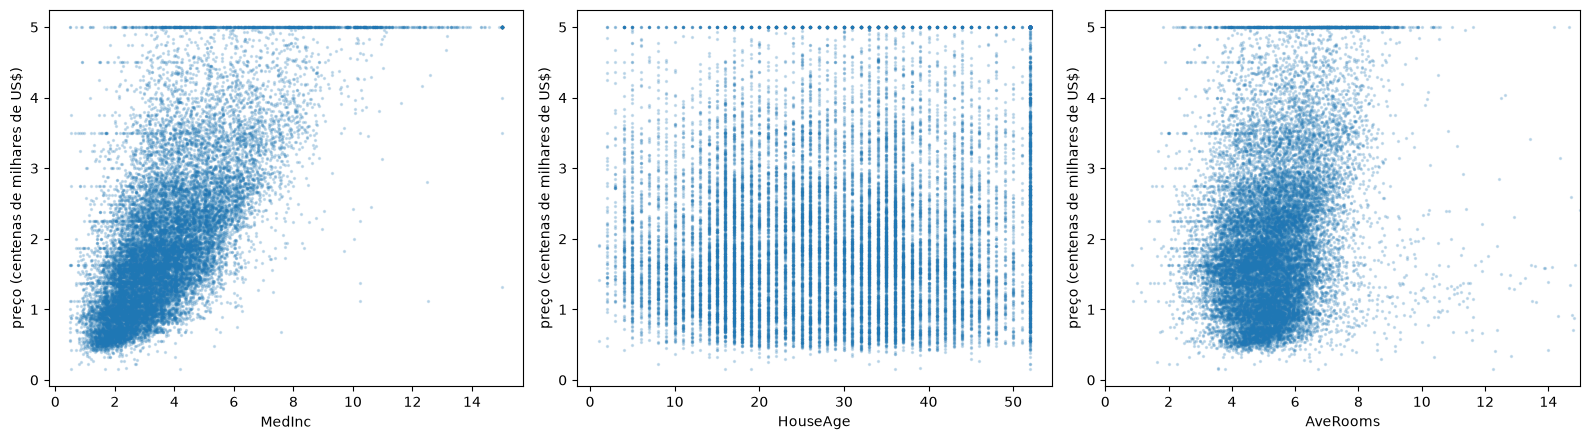

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['MedInc', 'HouseAge', 'AveRooms']):
    ax.scatter(X[col], y, s=2, alpha=0.2)
    ax.set_xlabel(col)
    ax.set_ylabel('preço (centenas de milhares de US$)')
axes[2].set_xlim(0, 15)   # corta os poucos outliers de AveRooms para enxergar a nuvem
plt.tight_layout()
plt.show()

- `MedInc`: relação claramente crescente; é a variável que mais se parece com uma reta contra o preço.
- `HouseAge`: quase nenhuma tendência visível sozinha.
- `AveRooms`: tendência fraca e muita dispersão.
- Nos três gráficos aparece a linha horizontal no topo, que é o teto de US$ 500 mil.

## Treino, validação e teste (70/15/15)

Primeiro separamos 30% dos dados; depois dividimos esses 30% ao meio entre validação e teste. `random_state=42` fixa o sorteio.

- **treino**: ajusta os parâmetros;
- **validação**: acompanha o custo durante o treino (e serviria para escolher hiperparâmetros, como a taxa de aprendizado);
- **teste**: usado uma única vez, no final, para medir o erro em dados nunca vistos.

In [5]:
x_raw = X.to_numpy()                   # (20640, 8)
y_raw = y.to_numpy().reshape(-1, 1)    # (20640, 1)

x_train_raw, x_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    x_raw, y_raw, test_size=0.3, random_state=42)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp_raw, y_temp_raw, test_size=0.5, random_state=42)

print('treino:   ', x_train_raw.shape)
print('validação:', x_val_raw.shape)
print('teste:    ', x_test_raw.shape)

treino:    (14448, 8)
validação: (3096, 8)
teste:     (3096, 8)


## Padronização

Igual ao 2.6: o `StandardScaler` é ajustado (`fit`) **só no treino** e depois aplicado (`transform`) à validação e ao teste, para não vazar informação desses conjuntos para o treino. Agora o `x_scaler` calcula uma média e um desvio padrão para **cada uma das 8 colunas**.

In [6]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

def to_tensor(a):
    return torch.from_numpy(a).float()

x_train = to_tensor(x_scaler.transform(x_train_raw))
y_train = to_tensor(y_scaler.transform(y_train_raw))
x_val = to_tensor(x_scaler.transform(x_val_raw))
y_val = to_tensor(y_scaler.transform(y_val_raw))
x_test = to_tensor(x_scaler.transform(x_test_raw))
y_test = to_tensor(y_scaler.transform(y_test_raw))

print('x_train:', x_train.shape, ' y_train:', y_train.shape)

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])


## Modelo

`nn.Linear(8, 1)`: `model.weight` tem shape (1, 8), um peso por variável, e `model.bias` tem shape (1,).

In [7]:
model = nn.Linear(8, 1)
print('weight:', model.weight.shape, ' bias:', model.bias.shape)

weight: torch.Size([1, 8])  bias: torch.Size([1])


## Treinamento

Mesma função de custo, otimizador e funções `train_epoch`/`validate_epoch` do 2.6. Cada época é um passo de gradiente com todo o treino.

In [8]:
lr = 0.1
n_epochs = 500
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

In [9]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()


def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

In [10]:
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_losses.append(train_epoch(model, optimizer, criterion, x_train, y_train))
    val_losses.append(validate_epoch(model, criterion, x_val, y_val))

    if (epoch + 1) % 100 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}')

Epoch[100/500], Train Loss: 0.3938, Val Loss: 0.4066
Epoch[200/500], Train Loss: 0.3908, Val Loss: 0.4039
Epoch[300/500], Train Loss: 0.3907, Val Loss: 0.4038
Epoch[400/500], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[500/500], Train Loss: 0.3907, Val Loss: 0.4037


### Curvas de custo de treino e de validação

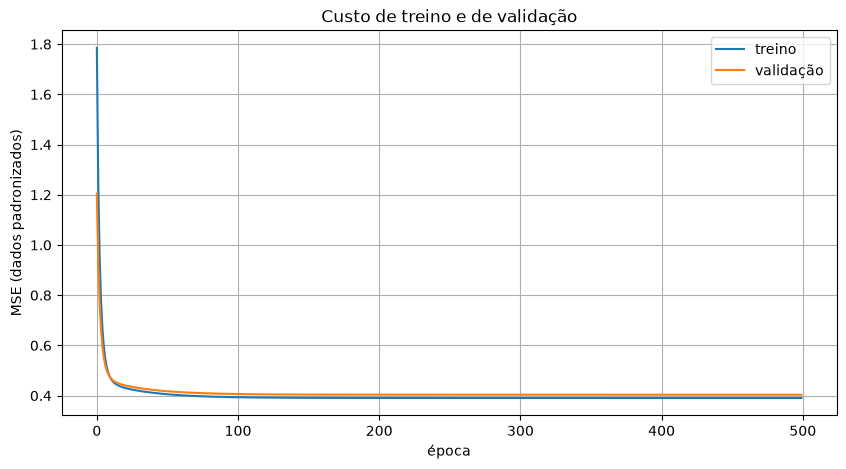

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='treino')
plt.plot(val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('MSE (dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

O custo cai rápido nas primeiras ~100 épocas e depois se estabiliza (treino ≈ 0,39, validação ≈ 0,40). As duas curvas ficam próximas, então não há sinal de overfitting: com só 9 parâmetros e 14 mil amostras de treino, o modelo é simples demais para decorar os dados.

## Avaliação no teste: RMSE em dólares

As previsões voltam à escala original com `y_scaler.inverse_transform` e são multiplicadas por 100.000 (o preço está em centenas de milhares de dólares).

O **baseline** é um "modelo" que ignora as entradas e sempre prevê o preço médio do treino. Um modelo útil precisa ser bem melhor que ele.

In [12]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_pred - y_true) ** 2))

model.eval()
with torch.no_grad():
    y_test_pred = y_scaler.inverse_transform(model(x_test).numpy())

baseline_pred = np.full_like(y_test_raw, y_train_raw.mean())

rmse_modelo = rmse(y_test_raw, y_test_pred) * 100_000
rmse_baseline = rmse(y_test_raw, baseline_pred) * 100_000

print(f'RMSE teste, regressão linear: US$ {rmse_modelo:,.0f}')
print(f'RMSE teste, baseline (média): US$ {rmse_baseline:,.0f}')
print(f'preço médio no teste:         US$ {y_test_raw.mean() * 100_000:,.0f}')
print(f'redução do erro:              {1 - rmse_modelo / rmse_baseline:.0%}')

RMSE teste, regressão linear: US$ 72,132
RMSE teste, baseline (média): US$ 114,992
preço médio no teste:         US$ 206,596
redução do erro:              37%


A regressão linear erra em média cerca de **US$ 72 mil** no teste, contra **US$ 115 mil** do baseline: o erro cai cerca de 37%. Ou seja, as 8 variáveis explicam boa parte do preço. Mesmo assim, US$ 72 mil é um erro grande diante de um preço médio de ~US$ 207 mil (cerca de 35%).

## Os 8 pesos aprendidos

bias (w0): 0.0
Latitude     -0.771
Longitude    -0.750
AveRooms     -0.259
AveOccup     -0.036
Population   -0.001
HouseAge      0.106
AveBedrms     0.301
MedInc        0.734
dtype: float32


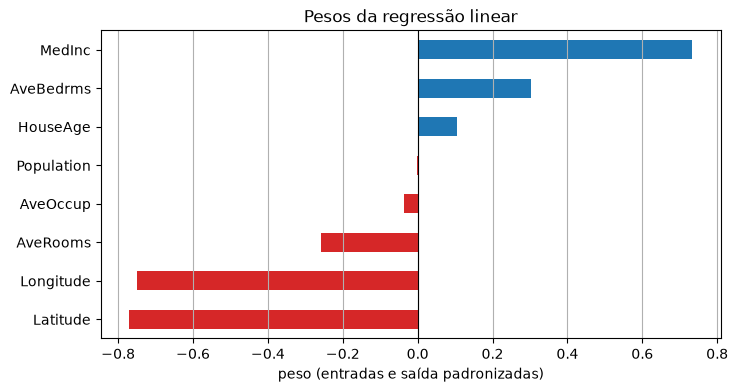

In [13]:
pesos = pd.Series(model.weight.detach().numpy().ravel(), index=X.columns).sort_values()
print('bias (w0):', round(model.bias.item(), 4))
print(pesos.round(3))

pesos.plot.barh(figsize=(8, 4), color=['tab:red' if p < 0 else 'tab:blue' for p in pesos])
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('peso (entradas e saída padronizadas)')
plt.title('Pesos da regressão linear')
plt.grid(True, axis='x')
plt.show()

**Quais variáveis mais aumentam o preço previsto?**

- `MedInc` (≈ +0,73): é o peso positivo mais forte, porque bairros de renda mais alta têm casas mais caras.
- `AveBedrms` (≈ +0,30) e `HouseAge` (≈ +0,11) vêm em seguida.

**Quais mais diminuem?**

- `Latitude` (≈ −0,77) e `Longitude` (≈ −0,75): ir para o norte ou para o leste (para o interior) reduz o preço. As casas mais caras estão no litoral, perto de São Francisco e de Los Angeles.
- `AveRooms` (≈ −0,26): à primeira vista é estranho, mas `AveRooms` e `AveBedrms` são muito correlacionadas, então o modelo divide o efeito entre as duas. Por isso o sinal de cada uma, isoladamente, não deve ser interpretado ao pé da letra.
- `AveOccup` e `Population` têm pesos quase nulos.

O bias ficou praticamente zero porque a saída está padronizada (média 0), assim como as entradas.

**Por que só faz sentido comparar os pesos porque as entradas foram padronizadas?**

Cada peso mede quanto o preço muda quando a variável aumenta **1 unidade**. Sem padronização, as unidades são diferentes: 1 unidade de `MedInc` são US$ 10 mil de renda, 1 unidade de `Population` é uma pessoa, e 1 unidade de `Latitude` é um grau (~110 km). Os pesos dependeriam dessas unidades, e não da importância da variável. Depois da padronização, 1 unidade passa a ser **1 desvio padrão** de cada variável. Então todos os pesos ficam na mesma escala ("quantos desvios padrão o preço muda quando a variável muda 1 desvio padrão") e podem ser comparados entre si.

## Conclusão

**O modelo é bom o suficiente?** É bem melhor que o baseline (erro ~37% menor), mas não é bom o suficiente para estimar o preço de uma casa específica: errar em média US$ 72 mil é muito. A regressão linear só consegue representar uma soma ponderada das variáveis, e o preço tem relações não lineares. Por exemplo, a localização não é uma reta em latitude e longitude: o que importa é estar perto do litoral e das grandes cidades.

**O que eu tentaria para melhorar:**

1. **Rede neural com camadas ocultas e ativação não linear** (por exemplo `nn.Linear(8, 64)` → `ReLU` → `nn.Linear(64, 1)`), para capturar relações não lineares. É o próximo passo natural do curso.
2. **Tratar os outliers** de `AveRooms`, `AveBedrms` e `AveOccup` (cortar valores extremos ou aplicar `log`).
3. **Criar variáveis melhores**, como a razão quartos/cômodos ou a distância até o litoral.
4. **Lidar com o teto de US$ 500 mil** do preço, por exemplo removendo essas amostras, já que o valor real delas é desconhecido.